# Initialization and sampling diagnostics at matched preparation budgets

This notebook is designed to audit the saved sixth optimization study without repeating its training. The frozen plan contains **36 ideal sampled runs** and **24 deterministic CPU controls**. Every start, seed, rejection, missed target, and inconclusive final interval is retained. Until matching completed artifacts are present, notebook execution stops instead of generating study data.

The cases are C4/C6 QAOA at depths one and two, and four-/six-spin open-chain VQE. Two prescribed starts per case distinguish initialization behavior, while exact-objective and expected-margin controls help inspect sampling and acceptance effects. These bounded controls do not certify the best achievable ansatz energy or general optimizer convergence. Equal preparation counts still permit different gate workloads and hardware costs.

Use the pinned Python 3.12 environment with the complete matching diagnostics artifact directory beside this notebook, or run from the checkout. Standalone auditing requires `optimization.py`, the generator snapshot, `runs.json`, `resources.json`, `circuit-manifest.json`, and its `circuits/` QASM files. The original QAOA and VQE papers provide algorithm context {cite:p}`opt_qaoa2014,opt_vqe2014`; Qiskit, NumPy and Matplotlib are credited at their pinned versions {cite:p}`opt_qiskit262,opt_numpy254,opt_matplotlib3112`. Our implementation, exposition and figures are original and MIT-licensed.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
sys.dont_write_bytecode = True

cwd = Path.cwd().resolve()
folders = [cwd / "assets/generated/optimization/diagnostics",
           cwd.parent / "assets/generated/optimization/diagnostics", cwd]
artifact_folder = next((folder.resolve() for folder in folders
                        if (folder / "runs.json").is_file()
                        and (folder / "optimization.py").is_file()), None)
if artifact_folder is None:
    raise FileNotFoundError("Save the complete diagnostics artifact directory, including runs.json, matching optimization.py and generator snapshots, resources.json, circuit-manifest.json and circuits/, beside this notebook, or run from the checkout.")
record_path = artifact_folder / "runs.json"
module_path = artifact_folder / "optimization.py"
generator_path = artifact_folder / "generate_optimization_diagnostics.py"
if not generator_path.is_file():
    raise FileNotFoundError("The matching diagnostics generator snapshot is required for this saved-record audit.")
record_bytes = record_path.read_bytes()
study = json.loads(record_bytes.decode("utf-8"))
source_bytes = module_path.read_bytes()
generator_bytes = generator_path.read_bytes()
implementation_sha256 = hashlib.sha256(source_bytes).hexdigest()
generator_sha256 = hashlib.sha256(generator_bytes).hexdigest()
assert study["provenance"]["implementation_sha256"] == implementation_sha256
assert study["provenance"]["generator_sha256"] == generator_sha256
spec = importlib.util.spec_from_file_location("optimization_diagnostics_notebook_source", module_path)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
# Execute precisely the bytes whose digest was checked, without bytecode writes.
exec(compile(source_bytes, str(module_path), "exec"), opt.__dict__)
assert Path(opt.__file__).resolve() == module_path
print({"mode": "saved-record audit; no training",
       "implementation_sha256": implementation_sha256,
       "generator_sha256": generator_sha256,
       "record_sha256": hashlib.sha256(record_bytes).hexdigest(),
       "python": platform.python_version(),
       "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib")}})

from collections import Counter
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import qasm3
from qiskit.quantum_info import Statevector

{'mode': 'saved-record audit; no training', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'generator_sha256': '0c0f3ff0f177dca99a00cc611261c3b6c82ce39be251e8d3a54026b0f5346f3e', 'record_sha256': 'b4316ad43a45458a390397599dc9b9a02d2810440e20ba912b7a77dfa7069567', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Frozen tasks, starts and allocations

QAOA maximizes expected cut on the even cycles C4/C6 with interleaved layer angles. The original start repeats $(\gamma,\beta)=(0.2,0.1)$; the alternative repeats $(0.6,0.4)$. It minimizes negative joint all-Z cut estimates. Its target remains expected cut divided by the independently enumerated classical optimum, at least **0.80**.

VQE uses one RY angle per qubit, followed by the ascending CX chain, for

$$H_n=-\sum_{q=0}^{n-1}Z_q+\frac12\sum_{q=0}^{n-2}X_qX_{q+1}.$$

Its original start has every angle 0.6; the alternative is the zero-angle vector. Independent all-Z and all-X groups retain covariance of the terms scored jointly from each bitstring. The target remains $(E-E_0)/n\le0.05$, where dense independent diagonalization supplies $E_0$.

Each case/start pair receives seeds `7`, `19`, `41` in distinct namespaces `30`–`41`. The twelve sweeps use four steps each of 0.4, 0.2 and 0.1 radians, with shots per group $b$, $2b$, $4b$:

| Run type | Initial shots/group | $b$ | Training calls | Training preparations |
|---|---:|---:|---:|---:|
| QAOA $p=1$ | 128 | 468 | 61 | 65,648 |
| QAOA $p=2$ | 128 | 260 | 109 | 65,648 |
| VQE $n=4$ | 64 | 130 | 109 | 65,648 |
| VQE $n=6$ | 64 | 90 | 157 | 65,648 |

Every sampled run consumes **65,648 training preparations**. Its final state receives fresh **16,384 shots/group**. The sampled collection therefore contains **3,672 calls**, **5,280 measured groups**, and **3,149,760 preparations**, including all proposals, incumbent refreshes and holdouts. The whole-family final confidence allowance 0.05 is split over **48 holdout groups** before observing counts.

Each of the twelve case/start pairs also has two deterministic CPU controls with the identical proposal schedule: exact means with effective SE zero, and exact means with true group population variances divided by the prescribed virtual shots. Together these controls use **2,424 exact oracle evaluations** and **zero quantum preparations**. Their prospective allocations are virtual comparison inputs, not sampled counts, QPU shots or actual gate consumption.

In [2]:
assert study["artifact_status"] == "complete", "Only completed derived exports can be audited."
recipe = study["recipe"]
assert recipe == opt.diagnostic_recipe(), "The saved record must bind to its unchanged recipe."
assert recipe["fixed_predeclared_recipe"]
assert recipe["validation_shots_per_group"] == 16_384
planned = recipe["planned"]
for key, expected in {"sampled_runs": 36, "objective_calls": 3_672, "group_batches": 5_280,
                      "total_shots": 3_149_760, "training_calls": 3_636,
                      "training_groups": 5_232, "validation_groups": 48,
                      "training_shots": 2_363_328, "validation_shots": 786_432}.items():
    assert planned[key] == expected, (key, planned[key], expected)
assert len(study["cases"]) == 6
assert len(study["controls"]) == 24
print({"completed_sampled_runs": sum(len(case["runs"]) for case in study["cases"]),
       "completed_CPU_controls": len(study["controls"]),
       "training_preparations_per_sampled_run": 65_648,
       "sampled_workload": planned})

{'completed_sampled_runs': 36, 'completed_CPU_controls': 24, 'training_preparations_per_sampled_run': 65648, 'sampled_workload': {'sampled_runs': 36, 'cpu_controls': 24, 'training_calls': 3636, 'validation_calls': 36, 'objective_calls': 3672, 'training_groups': 5232, 'validation_groups': 48, 'group_batches': 5280, 'training_shots': 2363328, 'validation_shots': 786432, 'total_shots': 3149760, 'measured_qubit_readouts': 15748800, 'shot_weighted_source_unitary_gates': 82488288, 'cpu_control_evaluations_per_mode': 1212, 'cpu_control_evaluations': 2424, 'cpu_control_final_audits': 24}}


## Independent states, objectives and group moments

The bounded checks below enumerate cycle cuts independently, build each spin-chain Hamiltonian as a dense matrix, and apply rotations and entangling permutations directly to amplitude vectors. They use Qiskit's little-endian wire convention. Group population variances include covariance among every term scored from the same bitstring. These classical calculations are numerical checks, not formal proofs.

In [3]:
cut_cache={}
hamiltonian_cache={}


def independent_cuts(n_qubits,edges):
    if not 2<=n_qubits<=6:
        raise ValueError("independent classical checks are capped at 6 qubits")
    key=(n_qubits,tuple(sorted(tuple(sorted(edge)) for edge in edges)))
    if key not in cut_cache:
        cut_cache[key]=np.array([sum(((z>>u)&1)!=((z>>v)&1) for u,v in edges)
                                 for z in range(1<<n_qubits)],dtype=float)
    return cut_cache[key]


def independent_qaoa_state(n_qubits,edges,parameters):
    values=independent_cuts(n_qubits,edges)
    if len(parameters)%2 or not parameters:
        raise ValueError("QAOA uses interleaved gamma,beta pairs")
    state=np.ones(1<<n_qubits,dtype=complex)/np.sqrt(1<<n_qubits)
    indices=np.arange(1<<n_qubits)
    for gamma,beta in zip(parameters[::2],parameters[1::2]):
        state*=np.exp(-1j*gamma*values)
        for wire in range(n_qubits):
            # Simultaneous amplitudes implement exp(-i beta X) independently.
            state=np.cos(beta)*state-1j*np.sin(beta)*state[indices^(1<<wire)]
    np.testing.assert_allclose(np.vdot(state,state).real,1.,rtol=0,atol=1e-12)
    return state


def independent_chain_hamiltonian(n_qubits):
    if not 2<=n_qubits<=6:
        raise ValueError("these dense VQE checks are limited to declared n<=6 cases")
    if n_qubits not in hamiltonian_cache:
        indices=np.arange(1<<n_qubits)
        z_values=np.array([-sum(1-2*((z>>q)&1) for q in range(n_qubits))
                           for z in indices],dtype=float)
        matrix=np.diag(z_values)
        for q in range(n_qubits-1):
            matrix+=.5*np.eye(1<<n_qubits)[:,indices^((1<<q)|(1<<(q+1)))]
        np.testing.assert_allclose(matrix,matrix.T,rtol=0,atol=1e-14)
        hamiltonian_cache[n_qubits]=(matrix,float(np.linalg.eigvalsh(matrix)[0]))
    return hamiltonian_cache[n_qubits]


def independent_chain_state(n_qubits,parameters):
    if len(parameters)!=n_qubits or not 2<=n_qubits<=6:
        raise ValueError("one RY angle per qubit is required for these declared cases")
    indices=np.arange(1<<n_qubits)
    state=np.zeros(1<<n_qubits,dtype=complex)
    state[0]=1
    for q,theta in enumerate(parameters):
        zeros=indices[(indices&(1<<q))==0]
        ones=zeros^(1<<q)
        before=state.copy()
        state[zeros]=np.cos(theta/2)*before[zeros]-np.sin(theta/2)*before[ones]
        state[ones]=np.sin(theta/2)*before[zeros]+np.cos(theta/2)*before[ones]
    for q in range(n_qubits-1):
        permutation=indices.copy()
        permutation[(indices&(1<<q))!=0]^=1<<(q+1)
        state=state[permutation]
    np.testing.assert_allclose(np.vdot(state,state).real,1.,rtol=0,atol=1e-12)
    return state


def independent_group_scores(algorithm,n_qubits,edges,group_name):
    if algorithm=="qaoa":
        return independent_cuts(n_qubits,edges)
    if group_name=="all_z":
        return np.array([-sum(1-2*((z>>q)&1) for q in range(n_qubits))
                         for z in range(1<<n_qubits)],dtype=float)
    if group_name=="all_x":
        return np.array([.5*sum((1-2*((z>>q)&1))*(1-2*((z>>(q+1))&1)) for q in range(n_qubits-1))
                         for z in range(1<<n_qubits)],dtype=float)
    raise ValueError("unexpected measurement group")


def independent_group_state(algorithm, n_qubits, edges, parameters, group_name):
    state = (independent_qaoa_state(n_qubits, edges, parameters) if algorithm == "qaoa"
             else independent_chain_state(n_qubits, parameters))
    if group_name == "all_x":
        indices = np.arange(1 << n_qubits)
        for wire in range(n_qubits):
            zeros = indices[(indices & (1 << wire)) == 0]
            ones = zeros ^ (1 << wire)
            before = state.copy()
            state[zeros] = (before[zeros] + before[ones]) / np.sqrt(2)
            state[ones] = (before[zeros] - before[ones]) / np.sqrt(2)
    elif group_name != "all_z":
        raise ValueError("unexpected measurement group")
    return state


def independent_group_moments(algorithm, n_qubits, edges, parameters, group_name):
    state = independent_group_state(algorithm, n_qubits, edges, parameters, group_name)
    scores = independent_group_scores(algorithm, n_qubits, edges, group_name)
    probabilities = np.abs(state) ** 2
    mean = float(probabilities @ scores)
    variance = float(probabilities @ (scores - mean) ** 2)
    return mean, variance


def interval_status(algorithm, value, radius):
    if algorithm == "qaoa":
        return "supported" if value - radius >= .80 else "missed" if value + radius < .80 else "inconclusive"
    return "supported" if value + radius <= .05 else "missed" if value - radius > .05 else "inconclusive"

In [4]:
def replay_search(run, initial, *, control=False):
    """Reconstruct the fixed polling order, decisions and final annotations."""
    calls = run["evaluations"]
    dimension = len(initial)
    assert len(calls) == 1 + 12 * (1 + 2 * dimension)
    assert [call["index"] for call in calls] == list(range(len(calls)))
    assert calls[0]["role"] == "initial" and not calls[0]["accepted"]
    point = (np.asarray(initial, dtype=float) + np.pi) % (2 * np.pi) - np.pi
    np.testing.assert_allclose(calls[0]["parameters"], point, rtol=0, atol=1e-12)
    mean_key = "objective_mean" if control else "objective_estimate"
    se_key = "effective_standard_error" if control else "estimated_standard_error"
    expected_index, current = 1, calls[0]
    accepted_indexes = set()
    for index, iteration in enumerate(run["iterations"]):
        assert iteration["index"] == index and iteration["step"] == (.4, .2, .1)[index // 4]
        assert iteration["incumbent_evaluation"] == expected_index
        expected_proposals = list(range(expected_index + 1, expected_index + 1 + 2 * dimension))
        assert iteration["proposal_evaluations"] == expected_proposals
        incumbent = calls[expected_index]
        proposals = [calls[item] for item in expected_proposals]
        assert incumbent["role"] == "incumbent" and not incumbent["accepted"]
        assert [(proposal["axis"], proposal["direction"]) for proposal in proposals] == [
            (axis, direction) for axis in range(dimension) for direction in (-1, 1)]
        np.testing.assert_allclose(iteration["parameters_before"], point, rtol=0, atol=1e-12)
        np.testing.assert_allclose(incumbent["parameters"], point, rtol=0, atol=1e-12)
        for proposal in proposals:
            assert proposal["role"] == "proposal"
            if control:
                assert proposal["iteration_index"] == incumbent["iteration_index"] == index
            expected = point.copy()
            expected[proposal["axis"]] += proposal["direction"] * iteration["step"]
            expected = (expected + np.pi) % (2 * np.pi) - np.pi
            np.testing.assert_allclose(proposal["parameters"], expected, rtol=0, atol=1e-12)
        # Python min keeps the first minimum in the frozen polling order.
        best = min(proposals, key=lambda call: call[mean_key])
        margin = 2 * math.hypot(incumbent[se_key], best[se_key])
        improvement = incumbent[mean_key] - best[mean_key]
        accepted = improvement > margin
        assert accepted == iteration["accepted"]
        assert best["index"] == iteration["best_proposal_evaluation"]
        np.testing.assert_allclose(iteration["comparison_margin"], margin, rtol=1e-12, atol=1e-14)
        np.testing.assert_allclose(iteration["exact_improvement" if control else "sampled_improvement"],
                                  improvement, rtol=1e-12, atol=1e-14)
        for proposal in proposals:
            assert proposal["accepted"] == (accepted and proposal["index"] == best["index"])
        if accepted: accepted_indexes.add(best["index"])
        current = best if accepted else incumbent
        point = np.asarray(current["parameters"])
        np.testing.assert_allclose(iteration["parameters_after"], point, rtol=0, atol=1e-12)
        expected_index += 1 + 2 * dimension
    assert len(run["iterations"]) == 12 and expected_index == len(calls)
    assert run["accepted_proposals"] == len(accepted_indexes)
    assert run["rejected_proposals"] == 24 * dimension - len(accepted_indexes)
    assert {call["index"] for call in calls if call["accepted"]} == accepted_indexes
    assert run["convergence_certified"] is False
    np.testing.assert_allclose(run["parameters"], point, rtol=0, atol=1e-12)
    if control:
        assert run["final_evaluation"] == current["index"]
        np.testing.assert_allclose(run["final_parameters"], point, rtol=0, atol=1e-12)
        np.testing.assert_allclose([run["final_exact_objective"], run["final_effective_standard_error"],
                                   run["final_expected_standard_error"]],
                                  [current["objective_mean"], current["effective_standard_error"],
                                   current["expected_standard_error"]], rtol=1e-12, atol=1e-14)
    else:
        np.testing.assert_allclose([run["final_training_estimate"], run["final_training_standard_error"]],
                                  [current["objective_estimate"], current["estimated_standard_error"]],
                                  rtol=1e-12, atol=1e-14)


def independent_quality(case, parameters, diagnostic):
    algorithm, width = case["algorithm"], case["n_qubits"]
    edges = tuple(tuple(edge) for edge in case.get("edges", ()))
    if algorithm == "qaoa":
        values = independent_cuts(width, edges)
        optimum = float(values.max())
        state = independent_qaoa_state(width, edges, parameters)
        raw_quality = float(np.abs(state) ** 2 @ values)
        quality = raw_quality / optimum
        np.testing.assert_array_equal(diagnostic["cut_values"], values)
        np.testing.assert_allclose([diagnostic["classical_optimum"], diagnostic["exact_expected_cut"],
                                   diagnostic["exact_approximation_ratio"]],
                                  [optimum, raw_quality, quality], rtol=0, atol=1e-10)
        return quality, optimum, None, quality >= .80
    matrix, ground = independent_chain_hamiltonian(width)
    state = independent_chain_state(width, parameters)
    raw_quality = float(np.vdot(state, matrix @ state).real)
    quality = (raw_quality - ground) / width
    np.testing.assert_allclose([diagnostic["ground_energy"], diagnostic["exact_energy"], diagnostic["energy_density_gap"]],
                              [ground, raw_quality, quality], rtol=0, atol=1e-10)
    return quality, width, ground, quality <= .05

## Saved measured decisions and deterministic controls

The completed notebook will replay every retained sampled count, descriptive standard error, incumbent refresh, proposal and acceptance from saved values. Independent exact moments will check the two control modes. A control's prescribed virtual allocation determines its comparison margin and does not enter the actual sampled resource ledger.

In [5]:
run_rows, measured_trace = [], []
seen_streams, namespaces, run_ids = set(), set(), set()
all_gate_counts = Counter()
total_calls = total_groups = total_shots = 0
case_map = {case["case_id"]: case for case in study["cases"]}
assert len(case_map) == 6
assert sorted((case["algorithm"], case["n_qubits"], case["p"]) for case in study["cases"]) == [
    ("qaoa", 4, 1), ("qaoa", 4, 2), ("qaoa", 6, 1), ("qaoa", 6, 2), ("vqe", 4, None), ("vqe", 6, None)]
for case in study["cases"]:
    algorithm, width = case["algorithm"], case["n_qubits"]
    edges = tuple(tuple(edge) for edge in case.get("edges", ()))
    if algorithm == "qaoa":
        assert len(edges) == width
        assert {tuple(sorted(edge)) for edge in edges} == {tuple(sorted((q, (q + 1) % width))) for q in range(width)}
    assert [(run["start_id"], run["seed"]) for run in case["runs"]] == [
        (start_id, seed) for start_id in ("original", "alternate") for seed in (7, 19, 41)]
    group_count = 1 if algorithm == "qaoa" else 2
    initial_shots = 128 if algorithm == "qaoa" else 64
    base = (468 if case["p"] == 1 else 260) if algorithm == "qaoa" else (130 if width == 4 else 90)
    for run in case["runs"]:
        start = opt.diagnostic_start(case, run["start_id"])
        expected_initial = ([value for _ in range(case["p"]) for value in ((.2, .1) if run["start_id"] == "original" else (.6, .4))]
                            if algorithm == "qaoa" else [(.6 if run["start_id"] == "original" else 0.)] * width)
        np.testing.assert_allclose(start["parameters"], expected_initial, rtol=0, atol=1e-14)
        np.testing.assert_allclose(run["initial"], expected_initial, rtol=0, atol=1e-14)
        namespaces.add(start["stream_id"])
        assert run["run_id"] == f"{case['case_id']}-{run['start_id']}-seed-{run['seed']}"
        assert run["run_id"] not in run_ids
        run_ids.add(run["run_id"])
        assert run["iteration_count"] == 12 and run["stop_reason"] == "fixed_schedule_exhausted"
        assert run["objective_evaluations"] == 1 + 12 * (1 + 2 * len(expected_initial))
        assert run["total_shots"] == 65_648
        assert run["exact_diagnostics_used_for_optimization"] is False
        expected_shots = {0: initial_shots}
        for iteration_index, iteration in enumerate(run["iterations"]):
            shots = base * (2 ** (iteration_index // 4))
            for index in [iteration["incumbent_evaluation"], *iteration["proposal_evaluations"]]:
                assert index not in expected_shots
                expected_shots[index] = shots
        assert set(expected_shots) == set(range(len(run["evaluations"])))
        weighted = Counter()
        for phase_index, phase, calls in ((0, "training", run["evaluations"]), (1, "validation", [run["validation"]])):
            for evaluation_index, call in enumerate(calls):
                total_calls += 1
                assert call["total_shots"] == sum(group["shots"] for group in call["groups"])
                assert [group["group"] for group in call["groups"]] == case["groups"]
                means, mean_variances = [], []
                for group_index, group in enumerate(call["groups"]):
                    assert group["shots"] == (expected_shots[evaluation_index] if phase == "training" else 16_384)
                    scores = independent_group_scores(algorithm, width, edges, group["group"])
                    counts = np.zeros(1 << width, dtype=np.int64)
                    for bits, number in group["counts"].items():
                        assert len(bits) == width and set(bits) <= {"0", "1"}
                        assert isinstance(number, int) and not isinstance(number, bool) and number > 0
                        counts[int(bits, 2)] = number
                    assert counts.sum() == group["shots"]
                    mean = float(counts @ scores / group["shots"])
                    variance = float(counts @ (scores - mean) ** 2 / (group["shots"] - 1))
                    se = math.sqrt(variance / group["shots"])
                    np.testing.assert_allclose([group["estimate"], group["sample_variance"], group["estimated_standard_error"]],
                                              [mean, variance, se], rtol=1e-12, atol=1e-12)
                    expected_range = (0., float(len(edges))) if algorithm == "qaoa" else ((-width, width) if group["group"] == "all_z" else (-(width - 1) / 2, (width - 1) / 2))
                    np.testing.assert_allclose([group["outcome_min"], group["outcome_max"]], expected_range, rtol=0, atol=1e-14)
                    means.append(mean); mean_variances.append(variance / group["shots"])
                    stream = (run["seed"], start["stream_id"], phase_index, evaluation_index, group_index)
                    assert tuple(group["rng"]["stream_key"]) == stream and stream not in seen_streams
                    assert group["rng"]["entropy"] == [run["seed"], start["stream_id"]]
                    assert group["rng"]["spawn_key"] == [phase_index, evaluation_index, group_index]
                    seen_streams.add(stream)
                    counts_ops = {name: number for name, number in group["circuit_gate_counts"].items() if name != "barrier"}
                    if algorithm == "qaoa":
                        expected_ops = {"h": width, "rz": len(edges) * case["p"], "rx": width * case["p"],
                                        "cx": 2 * len(edges) * case["p"], "measure": width}
                    else:
                        expected_ops = {"ry": width, "cx": width - 1, "measure": width}
                        if group["group"] == "all_x": expected_ops["h"] = width
                    assert counts_ops == expected_ops
                    weighted.update({gate: number * group["shots"] for gate, number in counts_ops.items()})
                    measured_trace.append({"case": case, "run": run, "phase": phase,
                                           "evaluation_index": evaluation_index, "group_index": group_index,
                                           "call": call, "group": group})
                    total_groups += 1; total_shots += group["shots"]
                expected_mean = -sum(means) if algorithm == "qaoa" else sum(means)
                np.testing.assert_allclose(call["objective_estimate"], expected_mean, rtol=0, atol=1e-11)
                np.testing.assert_allclose(call["estimated_standard_error"], math.sqrt(sum(mean_variances)), rtol=1e-12, atol=1e-12)
        replay_search(run, expected_initial)
        quality, denominator, ground, exact_met = independent_quality(case, run["parameters"], run["diagnostic"])
        assert run["target_met_audit"] == exact_met
        validation = run["validation"]
        np.testing.assert_allclose(validation["parameters"], run["parameters"], rtol=0, atol=1e-12)
        assert validation["total_shots"] == group_count * 16_384
        radius = sum((group["outcome_max"] - group["outcome_min"]) * math.sqrt(math.log(2 / (.05 / 48)) / (2 * group["shots"]))
                     for group in validation["groups"]) / denominator
        estimate = (-validation["objective_estimate"] / denominator if algorithm == "qaoa"
                    else (validation["objective_estimate"] - ground) / denominator)
        bound = validation["quality_bound"]
        np.testing.assert_allclose([bound["normalized_estimate"], bound["simultaneous_radius"]], [estimate, radius], rtol=0, atol=1e-12)
        assert bound["target_status"] == interval_status(algorithm, estimate, radius)
        assert bound["precision_supported"] == (radius <= .05)
        all_gate_counts.update(weighted)
        run_rows.append({"case": case, "run": run, "quality": quality, "exact_met": exact_met,
                         "estimate": estimate, "radius": radius, "status": bound["target_status"],
                         "weighted_counts": dict(weighted), "total_shots": run["total_shots"] + validation["total_shots"]})
assert namespaces == set(range(30, 42))
assert len(run_rows) == 36
assert (total_calls, total_groups, total_shots) == (3_672, 5_280, 3_149_760)
print({"retained_sampled_runs": len(run_rows), "replayed_sampled_sweeps": 432,
       "reconstructed_calls": total_calls, "measured_groups": total_groups,
       "actual_sampled_preparations": total_shots,
       "all_final_precision_radii_at_most_0.05": all(row["radius"] <= .05 for row in run_rows)})

{'retained_sampled_runs': 36, 'replayed_sampled_sweeps': 432, 'reconstructed_calls': 3672, 'measured_groups': 5280, 'actual_sampled_preparations': 3149760, 'all_final_precision_radii_at_most_0.05': True}


In [6]:
control_rows = []
control_calls = 0
expected_controls = [(case["case_id"], start["start_id"], mode) for case in recipe["cases"]
                     for start in case["starts"] for mode in recipe["control_modes"]]
assert [(run["case_id"], run["start_id"], run["mode"]) for run in study["controls"]] == expected_controls
for run in study["controls"]:
    case = case_map[run["case_id"]]
    algorithm, width = case["algorithm"], case["n_qubits"]
    edges = tuple(tuple(edge) for edge in case.get("edges", ()))
    initial = opt.diagnostic_start(case, run["start_id"])["parameters"]
    np.testing.assert_allclose(run["initial"], initial, rtol=0, atol=1e-14)
    assert run["quantum_preparations"] == 0 and run["seed"] is None and run["count_samples"] is None
    assert run["virtual_training_preparations"] == 65_648
    assert run["objective_evaluations"] == 1 + 12 * (1 + 2 * len(initial))
    assert run["iteration_count"] == 12 and run["stop_reason"] == "fixed_schedule_exhausted"
    expected_virtual = {0: case["initial_shots_per_group"]}
    for iteration_index, iteration in enumerate(run["iterations"]):
        shots = case["base_shots_per_group"] * (2 ** (iteration_index // 4))
        assert iteration["virtual_shots_per_group"] == shots
        for index in [iteration["incumbent_evaluation"], *iteration["proposal_evaluations"]]:
            assert index not in expected_virtual
            expected_virtual[index] = shots
    virtual_total = 0
    for index, call in enumerate(run["evaluations"]):
        assert call["quantum_preparations"] == 0 and call["count_samples"] is None
        assert call["seed"] is None
        assert call["virtual_shots_per_group"] == expected_virtual[index]
        assert call["virtual_preparations"] == len(case["groups"]) * expected_virtual[index]
        assert [group["group"] for group in call["groups"]] == case["groups"]
        means, variances = [], []
        for group in call["groups"]:
            assert group["quantum_preparations"] == 0 and group["count_samples"] is None
            assert "counts" not in group and "rng" not in group
            assert group["virtual_sampling_shots"] == expected_virtual[index]
            mean, variance = independent_group_moments(algorithm, width, edges, call["parameters"], group["group"])
            np.testing.assert_allclose([group["mean"], group["population_variance"], group["variance_of_mean"]],
                                      [mean, variance, variance / expected_virtual[index]], rtol=1e-11, atol=1e-12)
            scores = independent_group_scores(algorithm, width, edges, group["group"])
            np.testing.assert_allclose([group["outcome_min"], group["outcome_max"]],
                                      [scores.min(), scores.max()], rtol=0, atol=1e-14)
            means.append(mean); variances.append(variance / expected_virtual[index])
            virtual_total += expected_virtual[index]
        expected_mean = -sum(means) if algorithm == "qaoa" else sum(means)
        expected_se = math.sqrt(sum(variances))
        effective_se = 0. if run["mode"] == "exact-objective" else expected_se
        np.testing.assert_allclose([call["objective_mean"], call["expected_standard_error"], call["effective_standard_error"]],
                                  [expected_mean, expected_se, effective_se], rtol=1e-11, atol=1e-12)
    assert virtual_total == run["virtual_training_preparations"] == 65_648
    replay_search(run, initial, control=True)
    quality, _, _, exact_met = independent_quality(case, run["parameters"], run["diagnostic"])
    assert run["target_met_audit"] == exact_met
    control_rows.append({"case": case, "run": run, "quality": quality, "exact_met": exact_met})
    control_calls += len(run["evaluations"])
assert control_calls == 2_424
for mode in ("exact-objective", "expected-margin"):
    assert sum(row["run"]["objective_evaluations"] for row in control_rows if row["run"]["mode"] == mode) == 1_212
print({"retained_CPU_controls": len(control_rows), "replayed_control_sweeps": 288,
       "independently_checked_exact_oracle_evaluations": control_calls,
       "CPU_control_quantum_preparations": 0,
       "virtual_allocations_excluded_from_actual_sampled_totals": True})

{'retained_CPU_controls': 24, 'replayed_control_sweeps': 288, 'independently_checked_exact_oracle_evaluations': 2424, 'CPU_control_quantum_preparations': 0, 'virtual_allocations_excluded_from_actual_sampled_totals': True}


## Final confidence and complete source workload

Fresh final groups receive Hoeffding intervals using the frozen family allocation $\delta_{\rm group}=0.05/48$. Their target statuses distinguish support, misses and inconclusive intervals. They cover selected-state expectations conditional on training under ideal independent sampling; they do not certify training decisions or convergence.

The complete logical workload includes input preparation gates, objective interactions, measurement basis changes, rejected proposals and readout. Exact QASM deduplication is an export convenience and does not remove repeated preparations. Rotation synthesis, physical initialization/reset, routing and hardware feedback remain unmodeled. No physical projections are requested in this increment.

**Classical C4 reference coverage only.** The existing Lean result does not prove these QAOA/VQE circuits, stochastic decisions, control comparisons, or resource ledgers.

In [7]:
manifest_path = artifact_folder / "circuit-manifest.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes.decode("utf-8"))
assert manifest["total_group_batches"] == len(measured_trace) == 5_280
assert manifest["total_objective_calls"] == 3_672
unique = {row["sha256"]: row for row in manifest["unique_circuits"]}
assert len(unique) == manifest["unique_circuit_count"]
assert len(manifest["groups"]) == len(measured_trace)
checked_qasm = set()
final_prepared_state_checks = 0
for index, (trace, exported) in enumerate(zip(measured_trace, manifest["groups"])):
    case, run, call, group = trace["case"], trace["run"], trace["call"], trace["group"]
    assert exported["index"] == index
    for key, value in {"case_id": case["case_id"], "run_id": run["run_id"],
                       "start_id": run["start_id"], "seed": run["seed"], "phase": trace["phase"],
                       "evaluation_index": trace["evaluation_index"], "group_index": trace["group_index"],
                       "algorithm": case["algorithm"], "n_qubits": case["n_qubits"], "p": case["p"],
                       "measurement_basis": group["group"][-1],
                       "estimate": group["estimate"], "sample_variance": group["sample_variance"],
                       "estimated_standard_error": group["estimated_standard_error"],
                       "outcome_min": group["outcome_min"], "outcome_max": group["outcome_max"],
                       "parameters": call["parameters"], "counts": group["counts"],
                       "shots": group["shots"], "group": group["group"], "rng": group["rng"]}.items():
        assert exported[key] == value, (index, key)
    source = opt.diagnostic_group_circuit(case, call["parameters"], group["group"])
    source_counts = {name: int(number) for name, number in source.count_ops().items()}
    assert source_counts == group["circuit_gate_counts"] == exported["source_gate_counts"]
    assert source.depth() == group["circuit_depth"] == exported["source_depth"]
    assert source.num_qubits == group["logical_qubits"] == exported["logical_qubits"]
    raw = qasm3.dumps(source).encode("utf-8")
    sha = hashlib.sha256(raw).hexdigest()
    assert sha == group["source_qasm_sha256"] == exported["source_qasm_sha256"]
    assert group["source_qasm_file"] == exported["source_qasm_file"] == f"circuits/{sha}.qasm"
    circuit_record = unique[sha]
    assert circuit_record["file"] == group["source_qasm_file"]
    assert circuit_record["gate_counts"] == source_counts and circuit_record["depth"] == source.depth()
    assert circuit_record["logical_qubits"] == source.num_qubits
    if sha not in checked_qasm:
        assert (artifact_folder / circuit_record["file"]).read_bytes() == raw
        mapping = [[source.find_bit(item.qubits[0]).index, source.find_bit(item.clbits[0]).index]
                   for item in source.data if item.operation.name == "measure"]
        assert circuit_record["measurement_map"] == mapping
        checked_qasm.add(sha)
    if trace["phase"] == "validation":
        independent = independent_group_state(case["algorithm"], case["n_qubits"],
                                              tuple(tuple(edge) for edge in case.get("edges", ())),
                                              call["parameters"], group["group"])
        actual = Statevector.from_instruction(source.remove_final_measurements(inplace=False)).data
        np.testing.assert_allclose(abs(np.vdot(independent, actual)), 1., rtol=0, atol=1e-10)
        final_prepared_state_checks += 1
assert checked_qasm == set(unique)
assert final_prepared_state_checks == 48
ledger = opt.diagnostic_resources(study)
saved_ledger_bytes = (artifact_folder / "resources.json").read_bytes()
saved_ledger = json.loads(saved_ledger_bytes.decode("utf-8"))
for key in ("objective_calls", "group_batches", "training_shots", "validation_shots", "total_shots",
            "measured_qubit_readouts", "cpu_control_evaluations", "shot_weighted_source_unitary_gates",
            "weighted_gate_counts", "cpu_control_quantum_preparations"):
    assert saved_ledger[key] == ledger[key], key
assert ledger["weighted_gate_counts"] == dict(all_gate_counts) == recipe["expected_weighted_gate_counts"]
assert ledger["total_preparations"] == 3_149_760
assert ledger["measured_qubit_readouts"] == 15_748_800
assert ledger["shot_weighted_source_unitary_gates"] == 82_488_288
assert ledger["cpu_control_quantum_preparations"] == 0 and ledger["cpu_control_virtual_allocations_excluded"]
assert ledger["physical_resource_estimate"] is None and ledger["hardware_feedback_seconds"] is None
print({"all_actual_measured_groups_reconstructed": len(measured_trace),
       "unique_exact_QASM_sources_checked": len(checked_qasm),
       "final_prepared_state_and_basis_checks": final_prepared_state_checks,
       "manifest_sha256": hashlib.sha256(manifest_bytes).hexdigest(),
       "actual_sampled_preparations": ledger["total_preparations"],
       "actual_source_unitary_gates_weighted_by_shots": ledger["shot_weighted_source_unitary_gates"],
       "actual_qubit_readouts": ledger["measured_qubit_readouts"],
       "CPU_control_quantum_preparations": 0,
       "hardware_feedback_seconds": ledger["hardware_feedback_seconds"]})

{'all_actual_measured_groups_reconstructed': 5280, 'unique_exact_QASM_sources_checked': 1147, 'final_prepared_state_and_basis_checks': 48, 'manifest_sha256': '3ac01d8e8c60469a2ea0effadf11f21efa2fb747f3e61cc3d28ce67337ff1c94', 'actual_sampled_preparations': 3149760, 'actual_source_unitary_gates_weighted_by_shots': 82488288, 'actual_qubit_readouts': 15748800, 'CPU_control_quantum_preparations': 0, 'hardware_feedback_seconds': None}


## Quality, accepted moves and complete actual workload

The plots retain every prescribed sampled seed and both CPU control modes. Their exact values are independent post-training diagnostics; the final confidence flags remain separate. The decision-count plot records twelve fixed sweeps, not a convergence test. Exact-objective and expected-margin controls are different deterministic search paths, and the expected-margin path is not the expectation of a stochastic optimizer.

Preparation bars show actual sampled training and holdout counts. CPU control virtual allocations do not add quantum preparations. Source CX counts include every actual group's repetitions and therefore remain different even at equal training preparation counts.

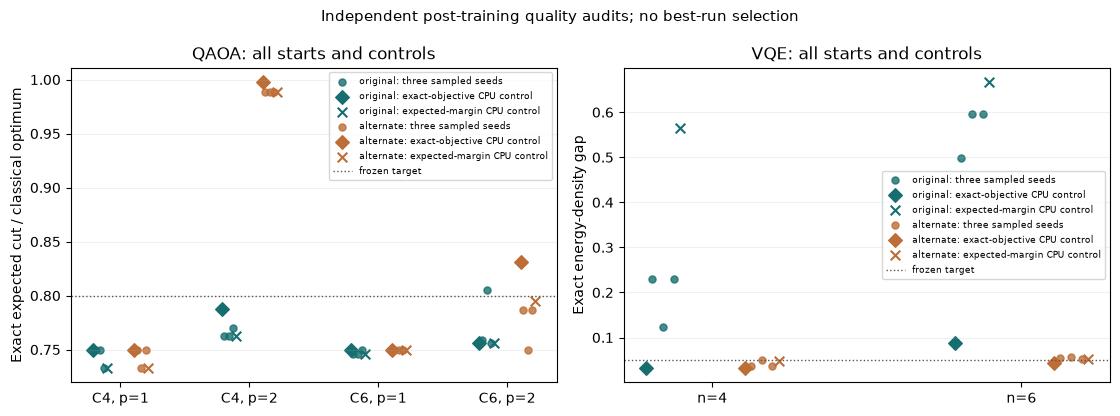

In [8]:
colors = {"original": "#176e70", "alternate": "#bd6d36"}
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.2))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    cases = [case for case in study["cases"] if case["algorithm"] == algorithm]
    labels = [f"C{case['n_qubits']}, p={case['p']}" if algorithm == "qaoa" else f"n={case['n_qubits']}" for case in cases]
    for index, case in enumerate(cases):
        for start_index, start_id in enumerate(("original", "alternate")):
            x = index + (-.16 if start_id == "original" else .16)
            points = [row for row in run_rows if row["case"]["case_id"] == case["case_id"] and row["run"]["start_id"] == start_id]
            ax.scatter(x + np.array([-.035, 0., .035]), [row["quality"] for row in points],
                       color=colors[start_id], s=26, alpha=.8, label=f"{start_id}: three sampled seeds" if index == 0 else None)
            for mode, marker, offset in (("exact-objective", "D", -.055), ("expected-margin", "x", .055)):
                control = next(row for row in control_rows if row["case"]["case_id"] == case["case_id"]
                               and row["run"]["start_id"] == start_id and row["run"]["mode"] == mode)
                ax.scatter(x + offset, control["quality"], color=colors[start_id], marker=marker, s=48,
                           label=f"{start_id}: {mode} CPU control" if index == 0 else None)
    target = .80 if algorithm == "qaoa" else .05
    ax.axhline(target, color="#555555", ls=":", lw=1, label="frozen target")
    ax.set(xticks=range(len(cases)), xticklabels=labels,
           ylabel="Exact expected cut / classical optimum" if algorithm == "qaoa" else "Exact energy-density gap",
           title=f"{algorithm.upper()}: all starts and controls")
    ax.grid(axis="y", alpha=.18)
    ax.legend(fontsize=6.8, loc="best")
fig.suptitle("Independent post-training quality audits; no best-run selection", fontsize=11)
fig.tight_layout(); display(fig); plt.close(fig)

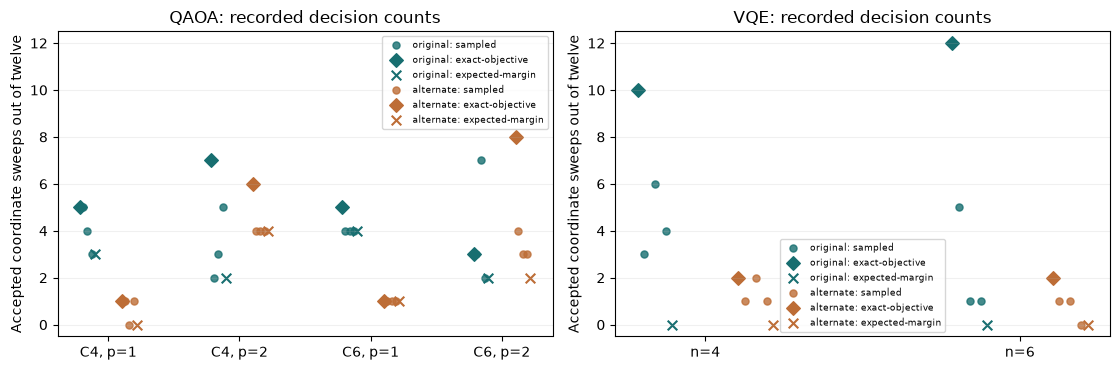

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.3, 3.8))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    cases = [case for case in study["cases"] if case["algorithm"] == algorithm]
    labels = [f"C{case['n_qubits']}, p={case['p']}" if algorithm == "qaoa" else f"n={case['n_qubits']}" for case in cases]
    for index, case in enumerate(cases):
        for start_id, offset in (("original", -.16), ("alternate", .16)):
            points = [row for row in run_rows if row["case"]["case_id"] == case["case_id"] and row["run"]["start_id"] == start_id]
            ax.scatter(index + offset + np.array([-.035, 0., .035]),
                       [sum(it["accepted"] for it in row["run"]["iterations"]) for row in points],
                       color=colors[start_id], s=26, alpha=.8, label=f"{start_id}: sampled" if index == 0 else None)
            for mode, marker, delta in (("exact-objective", "D", -.055), ("expected-margin", "x", .055)):
                control = next(row for row in control_rows if row["case"]["case_id"] == case["case_id"]
                               and row["run"]["start_id"] == start_id and row["run"]["mode"] == mode)
                ax.scatter(index + offset + delta, sum(it["accepted"] for it in control["run"]["iterations"]),
                           color=colors[start_id], marker=marker, s=48,
                           label=f"{start_id}: {mode}" if index == 0 else None)
    ax.set(xticks=range(len(cases)), xticklabels=labels, yticks=range(0, 13, 2), ylim=(-.5, 12.5),
           ylabel="Accepted coordinate sweeps out of twelve", title=f"{algorithm.upper()}: recorded decision counts")
    ax.legend(fontsize=6.8); ax.grid(axis="y", alpha=.18)
fig.tight_layout(); display(fig); plt.close(fig)

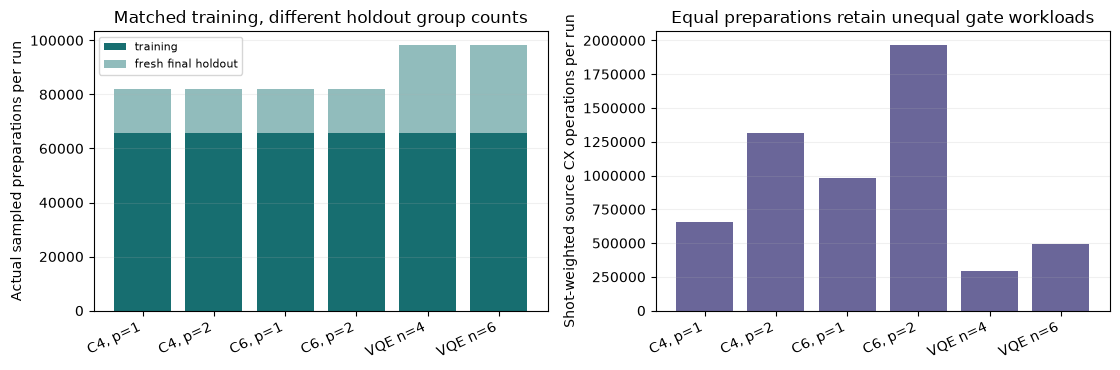

{'CPU_control_actual_preparations': 0, 'CPU_control_virtual_allocations_included_in_bars': False, 'rotation_synthesis_reset_routing_hardware_feedback': 'unmodeled'}


In [10]:
cases = study["cases"]
labels = [f"C{case['n_qubits']}, p={case['p']}" if case["algorithm"] == "qaoa" else f"VQE n={case['n_qubits']}" for case in cases]
whole_run = [next(row["total_shots"] for row in run_rows if row["case"]["case_id"] == case["case_id"]) for case in cases]
source_cx = [next(row["weighted_counts"]["cx"] for row in run_rows if row["case"]["case_id"] == case["case_id"]) for case in cases]
fig, axes = plt.subplots(1, 2, figsize=(11.3, 3.8))
x = np.arange(len(cases))
axes[0].bar(x, [65_648] * len(cases), color="#176e70", label="training")
axes[0].bar(x, np.array(whole_run) - 65_648, bottom=65_648, color="#91bcbc", label="fresh final holdout")
axes[0].set(ylabel="Actual sampled preparations per run", title="Matched training, different holdout group counts")
axes[0].legend(fontsize=8)
axes[1].bar(x, source_cx, color="#6a6699")
axes[1].set(ylabel="Shot-weighted source CX operations per run", title="Equal preparations retain unequal gate workloads")
for ax in axes:
    ax.set_xticks(x, labels, rotation=25, ha="right")
    ax.grid(axis="y", alpha=.18)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
fig.tight_layout(); display(fig); plt.close(fig)
print({"CPU_control_actual_preparations": 0, "CPU_control_virtual_allocations_included_in_bars": False,
       "rotation_synthesis_reset_routing_hardware_feedback": "unmodeled"})

## Retained results and interpretation

Every missed target and inconclusive final interval remains in the saved result. These observations compare the frozen starts and decision modes on six tiny inputs; failed local polling does not certify ansatz infeasibility, and better local outcomes do not establish global convergence. Prepared-state checks concern the stated inputs and readout bases, not all-input unitary equivalence.

The actual sampled logical ledger is separate from CPU reference cost and virtual control annotations. This increment has no physical projection, calibrated device noise or measured hardware feedback. **Classical C4 reference coverage only** remains the formal scope.

In [11]:
for algorithm in ("qaoa", "vqe"):
    for start_id in ("original", "alternate"):
        points = [row for row in run_rows if row["case"]["algorithm"] == algorithm and row["run"]["start_id"] == start_id]
        print({"algorithm": algorithm, "start": start_id, "retained_sampled_runs": len(points),
               "exact_target_hits": sum(row["exact_met"] for row in points),
               "exact_target_misses": sum(not row["exact_met"] for row in points),
               "simultaneous_holdout_statuses": dict(Counter(row["status"] for row in points))})
        for mode in ("exact-objective", "expected-margin"):
            controls = [row for row in control_rows if row["case"]["algorithm"] == algorithm
                        and row["run"]["start_id"] == start_id and row["run"]["mode"] == mode]
            print({"CPU_control_mode": mode, "algorithm": algorithm, "start": start_id,
                   "retained_controls": len(controls), "exact_target_hits": sum(row["exact_met"] for row in controls),
                   "quantum_preparations": 0})
print("Saved sampled decisions, CPU control moments and margins, independent final references, simultaneous readout bounds, exact-QASM sources and complete logical workloads checked without retraining.")

{'algorithm': 'qaoa', 'start': 'original', 'retained_sampled_runs': 12, 'exact_target_hits': 1, 'exact_target_misses': 11, 'simultaneous_holdout_statuses': {'missed': 11, 'inconclusive': 1}}
{'CPU_control_mode': 'exact-objective', 'algorithm': 'qaoa', 'start': 'original', 'retained_controls': 4, 'exact_target_hits': 0, 'quantum_preparations': 0}
{'CPU_control_mode': 'expected-margin', 'algorithm': 'qaoa', 'start': 'original', 'retained_controls': 4, 'exact_target_hits': 0, 'quantum_preparations': 0}
{'algorithm': 'qaoa', 'start': 'alternate', 'retained_sampled_runs': 12, 'exact_target_hits': 3, 'exact_target_misses': 9, 'simultaneous_holdout_statuses': {'missed': 7, 'supported': 3, 'inconclusive': 2}}
{'CPU_control_mode': 'exact-objective', 'algorithm': 'qaoa', 'start': 'alternate', 'retained_controls': 4, 'exact_target_hits': 2, 'quantum_preparations': 0}
{'CPU_control_mode': 'expected-margin', 'algorithm': 'qaoa', 'start': 'alternate', 'retained_controls': 4, 'exact_target_hits': 1, 